# 04 · Anomaly detection in grid measurements with an autoencoder
**Level 2 · Descriptive analytics (unsupervised)** &nbsp;|&nbsp; Course link: *Module 4 – AI-based data and machine
learning approaches: anomaly detection using auto-encoders*

Grid operators receive thousands of measurements every few seconds. Some are wrong. The course distinguishes three
sources of anomalies:
1. **measurement errors** – a faulty sensor,
2. **malicious manipulation** – a cyber-attacker injects false data (FDI) to mislead the operator,
3. **unexpected physical events** – real but unusual situations (e.g. an unknown fast charger).

Labelled examples of anomalies are rare, so we use **one-class learning**: an autoencoder is trained on *normal*
snapshots only and flags anything it cannot reconstruct well.

## How it works
The encoder compresses a measurement vector $x\in\mathbb{R}^d$ into a small code $z$; the decoder reconstructs it:
$$z = f_{\text{enc}}(x),\qquad \hat x = g_{\text{dec}}(z),\qquad
  \text{train: } \min \frac1n\sum_i \lVert x_i - \hat x_i\rVert^2 \text{ on normal data only}$$
Because grid measurements obey physics (Kirchhoff, Ohm), normal snapshots lie on a low-dimensional "manifold" that the
bottleneck learns. A snapshot that violates these relations is reconstructed badly:
$$\text{anomaly if } e(x)=\lVert x-\hat x\rVert^2 > \tau,\qquad \tau = 99^{\text{th}}\text{ percentile of } e \text{ on normal validation data}.$$

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score
from energy_ai import snapshots, simbench_grid, fast_pf, get_device, set_seed, style
style(); set_seed(0)
device = get_device()

Using device: xpu (Intel(R) UHD Graphics)


## 1. Normal data: 4 000 snapshots of a semi-urban LV grid
Each snapshot is one random 15-minute step of the SimBench year. "Sensors" measure every bus voltage and every
cable's active power flow (86 measurements), with realistic noise.

In [2]:
CODE = "1-LV-semiurb4--0-sw"
d = snapshots(CODE, n=4000, seed=0)
rng = np.random.default_rng(0)

def measure(vm, p, rng):
    """Add sensor noise: 0.1 % on voltages, 1 % (+0.1 kW) on power flows."""
    return pd.concat([vm + rng.normal(0, 0.001, vm.shape), p + rng.normal(0, 1, p.shape) * (0.01 * p.abs() + 1e-4)], axis=1)

X = measure(d["vm"], d["line_p"] * 1000, rng)          # power in kW
X.columns = [f"V_{c}" for c in d["vm"].columns] + [f"P_{c}" for c in d["line_p"].columns]
print("measurement matrix:", X.shape)
idx = rng.permutation(len(X)); n_tr, n_va = int(0.7 * len(X)), int(0.15 * len(X))
tr, va, te = X.iloc[idx[:n_tr]], X.iloc[idx[n_tr:n_tr + n_va]], X.iloc[idx[n_tr + n_va:]]
mu, sd = tr.mean(), tr.std() + 1e-9
Z = lambda df: ((df - mu) / sd).values.astype(np.float32)

measurement matrix: (4000, 86)


## 2. Create the three kinds of anomalies (test set only)

In [3]:
def sensor_faults(df, rng):
    out, where = df.copy(), []
    for i in range(len(out)):
        j = rng.integers(out.shape[1])
        col = out.columns[j]
        out.iat[i, j] = out.iat[i, j] * (1.03 if col.startswith("V_") else 1.5) if rng.random() < 0.5 else 0.0  # drift or dead sensor
        where.append(j)
    return out, np.array(where)

def fdi_attack(df, rng, lo, hi, n_bus=6, delta=0.004):
    """Attacker shifts a group of 6 voltages by ±0.004 p.u. but keeps every value inside the range normally seen for
    that sensor (a careful attacker avoids obvious outliers), so per-value range checks cannot see it."""
    out = df.copy(); vcols = [c for c in out.columns if c.startswith("V_")]
    for i in range(len(out)):
        start = rng.integers(0, len(vcols) - n_bus)
        cols = vcols[start:start + n_bus]
        new = out.iloc[i][cols] + delta * rng.choice([-1, 1])
        out.loc[out.index[i], cols] = np.clip(new, lo[cols] + 1e-4, hi[cols] - 1e-4)
    return out

def physical_event(times, rng, kw=60.0):
    """A real but unusual event: an unknown 60 kW fast charger at a random household (re-run power flow)."""
    net, prof = simbench_grid(CODE)
    vm, pl = [], []
    for t in times:
        net.load["p_mw"] = prof[("load", "p_mw")].loc[t].values; net.load["q_mvar"] = prof[("load", "q_mvar")].loc[t].values
        net.sgen["p_mw"] = prof[("sgen", "p_mw")].loc[t].values
        net.load.loc[rng.integers(len(net.load)), "p_mw"] += kw / 1000
        fast_pf(net); vm.append(net.res_bus.vm_pu.values.copy()); pl.append(net.res_line.p_from_mw.values.copy())
    vm = pd.DataFrame(vm, index=times, columns=d["vm"].columns); pl = pd.DataFrame(pl, index=times, columns=d["line_p"].columns)
    out = measure(vm, pl * 1000, rng); out.columns = X.columns
    return out

n_anom = 200
base = te.sample(n_anom, random_state=1)
A_sensor, sensor_idx = sensor_faults(base, rng)
lo, hi = tr.min(), tr.max()                       # normal range of every sensor (training data)
A_fdi = fdi_attack(base, rng, lo, hi)
A_phys = physical_event(base.index, rng)
print("normal test:", len(te), "| sensor faults:", len(A_sensor), "| FDI attacks:", len(A_fdi), "| physical events:", len(A_phys))

# naive range check: is every measurement inside the range seen in training?
range_flag = lambda df: ((df < lo) | (df > hi)).any(axis=1).mean()
print(f"simple range check catches: FDI {range_flag(A_fdi):.0%}, physical events {range_flag(A_phys):.0%}, "
      f"sensor faults {range_flag(A_sensor):.0%}, false alarms on normal {range_flag(te):.0%}")

normal test: 600 | sensor faults: 200 | FDI attacks: 200 | physical events: 200
simple range check catches: FDI 2%, physical events 100%, sensor faults 74%, false alarms on normal 3%


The min/max check catches dead sensors and the big physical event, but it is **blind to the FDI attack**, because every
falsified value is plausible on its own. What is wrong is the **relation** between measurements: some voltages moved
but the flows that should cause such a change did not. That is what an autoencoder learns.

## 3. Train the autoencoder (normal data only)

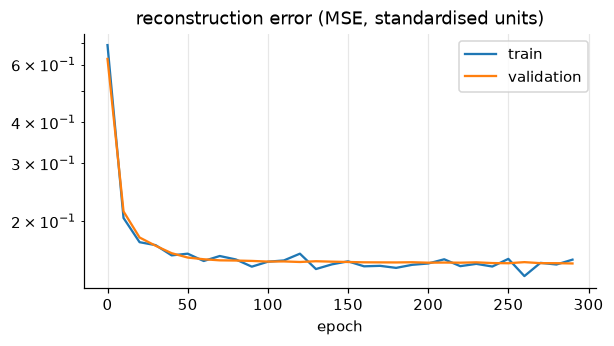

threshold τ = 0.2544 (99th percentile of normal validation error)


In [4]:
d_in = X.shape[1]
model = nn.Sequential(nn.Linear(d_in, 64), nn.ReLU(), nn.Linear(64, 16), nn.ReLU(), nn.Linear(16, 6),      # encoder → 6-d code
                      nn.ReLU(), nn.Linear(6, 16), nn.ReLU(), nn.Linear(16, 64), nn.ReLU(), nn.Linear(64, d_in)).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-5)
Xtr, Xva = torch.tensor(Z(tr), device=device), torch.tensor(Z(va), device=device)
hist = []
for epoch in range(300):
    model.train()
    for b in torch.randperm(len(Xtr)).to(device).split(128):   # permutation made on CPU: sort/randperm kernels fail on this iGPU for some sizes
        loss = ((model(Xtr[b]) - Xtr[b]) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    if epoch % 10 == 0:
        model.eval()
        with torch.no_grad():
            hist.append((epoch, loss.item(), ((model(Xva) - Xva) ** 2).mean().item()))
h = pd.DataFrame(hist, columns=["epoch", "train", "validation"]).set_index("epoch")
ax = h.plot(logy=True, figsize=(6, 3), title="reconstruction error (MSE, standardised units)"); plt.show()

def recon_error(df):
    model.eval()
    with torch.no_grad():
        x = torch.tensor(Z(df), device=device)
        return ((model(x) - x) ** 2).cpu().numpy()          # per-feature squared error

tau = np.quantile(recon_error(va).mean(1), 0.99)
print(f"threshold τ = {tau:.4f} (99th percentile of normal validation error)")

## 4. Results

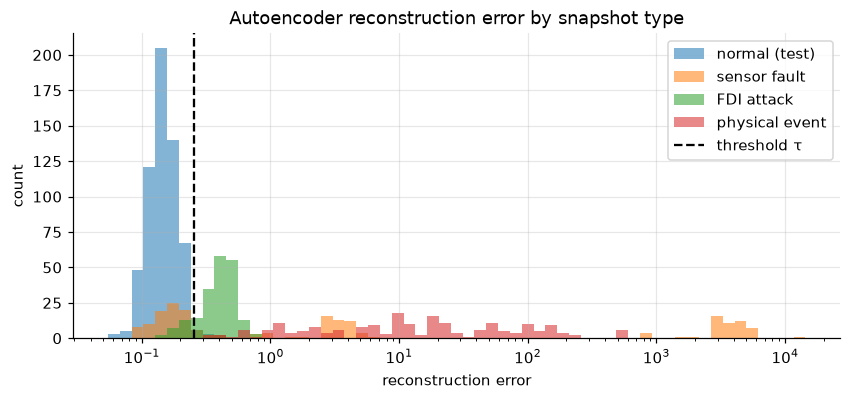

,false alarms on normal,detected: sensor fault,detected: FDI attack,detected: physical event,ROC-AUC (all)
method,,,,,
Autoencoder,1.5%,58.0%,87.0%,100.0%,0.939
PCA (linear AE),0.2%,54.5%,66.5%,99.0%,0.936
Isolation forest,1.3%,1.5%,1.5%,62.0%,0.741


In [5]:
sets = {"normal (test)": te, "sensor fault": A_sensor, "FDI attack": A_fdi, "physical event": A_phys}
errs = {k: recon_error(v).mean(1) for k, v in sets.items()}

fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.logspace(np.log10(min(e.min() for e in errs.values())), np.log10(max(e.max() for e in errs.values())), 60)
for k, e in errs.items():
    ax.hist(e, bins=bins, alpha=0.55, label=k)
ax.axvline(tau, color="k", ls="--", label="threshold τ"); ax.set_xscale("log")
ax.set(xlabel="reconstruction error", ylabel="count", title="Autoencoder reconstruction error by snapshot type"); ax.legend()
plt.show()

# baselines: PCA reconstruction (a *linear* autoencoder) and Isolation Forest
pca = PCA(n_components=6).fit(Z(tr))
pca_err = lambda df: ((Z(df) - pca.inverse_transform(pca.transform(Z(df)))) ** 2).mean(1)
tau_pca = np.quantile(pca_err(va), 0.99)
iso = IsolationForest(n_estimators=300, random_state=0).fit(Z(tr))
iso_score = lambda df: -iso.score_samples(Z(df))
tau_iso = np.quantile(iso_score(va), 0.99)

rows = []
for name, score, t in (("Autoencoder", lambda df: recon_error(df).mean(1), tau), ("PCA (linear AE)", pca_err, tau_pca),
                       ("Isolation forest", iso_score, tau_iso)):
    r = {"method": name, "false alarms on normal": (score(te) > t).mean()}
    for k in ("sensor fault", "FDI attack", "physical event"):
        r[f"detected: {k}"] = (score(sets[k]) > t).mean()
    allx = pd.concat([te, A_sensor, A_fdi, A_phys]); y = np.r_[np.zeros(len(te)), np.ones(3 * n_anom)]
    r["ROC-AUC (all)"] = roc_auc_score(y, score(allx))
    rows.append(r)
res = pd.DataFrame(rows).set_index("method")
display(res.style.format("{:.1%}", subset=[c for c in res.columns if c != "ROC-AUC (all)"]).format("{:.3f}", subset=["ROC-AUC (all)"]))

### Which sensor is wrong? Localisation from per-feature errors
For a sensor fault, the measurement with the largest reconstruction error usually *is* the faulty sensor.

faulty sensor correctly identified in 64% of sensor-fault snapshots


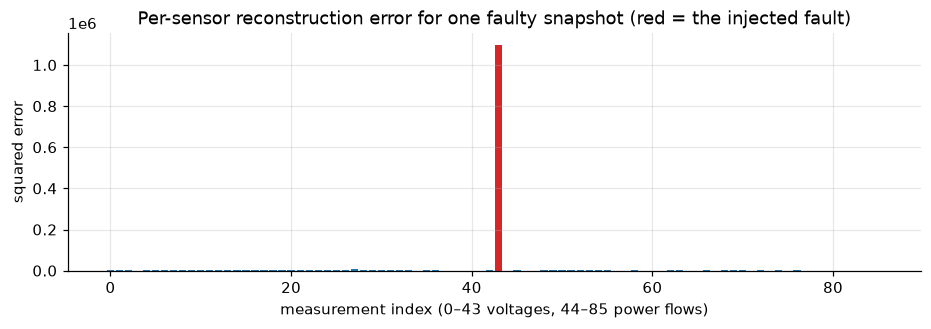

In [6]:
pf = recon_error(A_sensor)
hit = (pf.argmax(1) == sensor_idx).mean()
print(f"faulty sensor correctly identified in {hit:.0%} of sensor-fault snapshots")
i = int(np.argmax(errs["sensor fault"]))
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.bar(range(d_in), pf[i], color=["tab:red" if j == sensor_idx[i] else "tab:blue" for j in range(d_in)])
ax.set(xlabel="measurement index (0–43 voltages, 44–85 power flows)", ylabel="squared error",
       title="Per-sensor reconstruction error for one faulty snapshot (red = the injected fault)"); plt.show()

## Key takeaways
* One-class learning needs **only normal data**: ideal when anomalies and cyber-attacks are rare and unknown.
* The autoencoder detects inconsistencies *between* measurements (FDI) that per-value range checks miss.
* On the subtle FDI attacks the non-linear autoencoder clearly beats its linear cousin PCA (see the table), and both
  beat a generic Isolation Forest, which does not exploit the physical structure of the data.
* Not every sensor fault is detectable: a fault on a sensor measuring an (almost) empty cable barely changes the
  reading, so a ~55–60 % detection rate is expected here; the large faults are all caught.
* Per-feature errors localise the faulty sensor, giving operators an explanation, not just an alarm.
* Physical events are *real*; operators still want them flagged, but must not "correct" them away.

**Try it yourself:** make the attack stealthier (`delta=0.003`, `n_bus=3`) or the bottleneck larger (16) and watch
detection rates; notebook 14 shows attacks that are designed to be *invisible* to physics-based detectors.